# A pressure&ndash;enthalpy chart for R-448A, a refrigerant blend

Walk into a supermarket built before about 2015 and the display cases were almost certainly
cooled by **R-404A**, a blend with a 100-year global warming potential near 3900. Its
phase-down has moved much of that equipment to **R-448A**, a five-component blend with about
a third of the warming potential, formulated to run in the same compressors.

R-448A is not a pure substance, and that changes its chart. A pure fluid at fixed pressure
boils at one temperature, so its isotherms run flat across the two-phase dome, as they do on
the methane and nitrogen charts of Figures 3.3-2 and 3.3-3. A **zeotropic** blend starts to
boil at its **bubble point** and finishes at its **dew point**, several kelvin higher,
because the more volatile components leave the liquid first. The difference is the
**temperature glide**, and on R-448A's chart every isotherm slopes across the dome by that
amount.

This notebook draws that chart from the Peng&ndash;Robinson equation of state, with the van
der Waals one-fluid mixing rules of Section 9.4, the same equation used for the pure-fluid
charts of Chapter 3. Each of the five components needs three constants and an ideal-gas heat
capacity, and four of the ten pairs need a binary interaction parameter. The chart is then
checked against a refrigeration cycle of the kind worked in Section 5.2.

SIS is Stanley I. Sandler, *Chemical, Biochemical, and Engineering Thermodynamics*.

Eric Furst  
November 2026

In [1]:
# --- Colab bootstrap -------------------------------------------------------
# No-op when the thermo package is already alongside this notebook (the normal
# case: you cloned the repository and are running from code/ch5/). In Colab
# there is no repository, so fetch the package and the property data.
import os, sys
if not (os.path.isdir('../thermo') or os.path.isdir('thermo')):
    # rm -rf first: git clone REFUSES an existing directory, and under `!` that
    # failure is silent -- a half-finished earlier clone would otherwise leave an
    # empty thermo/ and surface as a baffling ImportError further down.
    !rm -rf /tmp/cbet6e
    !git clone -q --depth 1 https://github.com/emfurst/cbet6e.git /tmp/cbet6e
    !cp -r /tmp/cbet6e/code/thermo /tmp/cbet6e/code/data .
    sys.path.insert(0, '.')
else:
    sys.path.insert(0, '..')
# ---------------------------------------------------------------------------

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

from thermo import PengRobinson
from thermo.pr_mixture import PRMixture
from thermo.ph_chart import ph_chart
from thermo.ph_chart_blend import BlendChartFluid
from thermo.charts import use_book_style

## 1. The five components

R-448A is defined by ASHRAE Standard 34 as R-32/R-125/R-1234yf/R-134a/R-1234ze(E) in
the mass proportions **26/26/20/21/7**. Three are hydrofluorocarbons (R-32, R-125 and
R-134a), and two are the hydrofluoro-olefins of `code/ch3/refrigerant_comparison.ipynb`,
whose warming potential is near 1.

**Constants.** $T_c$ and $P_c$ are the critical points of each fluid's reference equation of
state: Tillner-Roth and Yokozeki (1997) for R-32, Lemmon and Jacobsen (2005) for R-125,
Richter, McLinden and Lemmon (2011) for R-1234yf, Tillner-Roth and Baehr (1994) for R-134a,
and Thol and Lemmon (2016) for R-1234ze(E). Each $\omega$ agrees with its definition,
Eq. 6.6-3, applied to the reference vapor pressure. The three fluids shared with
`refrigerant_comparison.ipynb` carry the same constants there and here.

**Ideal-gas heat capacities** are cubic polynomials in the Appendix A.II form,
$C_P^* = a + bT + cT^2 + dT^3$ in J/(mol K), fitted over 200&ndash;520 K to the ideal-gas
parts of the same five reference equations. Each fit is within 0.6 % of its reference over
that range. Every enthalpy on the chart is an ideal-gas enthalpy plus a departure function,
so $C_P^*$ sets the spacing of the isotherms in the vapor region.

In [3]:
#   name           M (g/mol)  Tc (K)    Pc (Pa)    omega    Cp* = a + bT + cT^2 + dT^3 (J/(mol K))          mass %
COMP = {
    "R-32":        (52.024,   351.255,  5.7826e6,  0.2769,  (37.266, -0.067305,  3.8806e-4, -3.2969e-7),  26),
    "R-125":       (120.021,  339.173,  3.6183e6,  0.3052,  (25.089,  0.2686,   -1.0119e-4, -6.5422e-8),  26),
    "R-1234yf":    (114.042,  367.85,   3.3822e6,  0.2760,  (18.868,  0.33155,  -1.6899e-4, -4.1665e-8),  20),
    "R-134a":      (102.031,  374.21,   4.0593e6,  0.3269,  (17.104,  0.28479,  -2.2871e-4,  1.2643e-7),  21),
    "R-1234ze(E)": (114.042,  382.51,   3.6349e6,  0.3132,  (30.161,  0.2962,   -2.5385e-4,  1.4187e-7),   7),
}
names = list(COMP)
M = np.array([COMP[n][0] for n in names])
w = np.array([COMP[n][5] for n in names]) / 100.0
z = (w / M) / np.sum(w / M)                       # mass fractions -> mole fractions

print(f"{'':<13}{'mass %':>8}{'mole %':>8}")
for n, wi, zi in zip(names, w, z):
    print(f"{n:<13}{100*wi:8.1f}{100*zi:8.1f}")
print(f"\nmolar mass of the blend: {z @ M:.2f} g/mol")

               mass %  mole %
R-32             26.0    43.1
R-125            26.0    18.7
R-1234yf         20.0    15.1
R-134a           21.0    17.8
R-1234ze(E)       7.0     5.3

molar mass of the blend: 86.28 g/mol


R-32 is a quarter of the mass and **43 % of the molecules**. It is the lightest component by
a factor of two and the most volatile, so it is also the component that leaves the liquid
first when the blend boils.

## 2. Binary interaction parameters

Peng&ndash;Robinson's mixing rule $a_{ij} = (1 - k_{ij})\sqrt{a_i a_j}$ has one adjustable
number per pair. The first test is the prediction with every $k_{ij} = 0$, against the
blend's bubble and dew pressures from a reference model: CoolProp 8.1 (Bell, Wronski, Quoilin
and Lemort, *Ind. Eng. Chem. Res.* **53**, 2498 (2014)), which combines the five reference
equations above with binary mixing functions fitted to measured data.

In [4]:
# The reference: CoolProp 8.1.0's R-448A model, (bubble P, dew P) in MPa at each deg C.
REF_SAT = {
     -40: (0.1355, 0.0997),
     -20: (0.3110, 0.2431),
       0: (0.6233, 0.5106),
      20: (1.1272, 0.9598),
      40: (1.8831, 1.6599),
      60: (2.9573, 2.7006),
}

pure = [PengRobinson(Tc=c[1], Pc=c[2], omega=c[3], name=n, cp=c[4]) for n, c in COMP.items()]


def compare(mix, label):
    print(label)
    print(f"{'T (C)':>7}{'bubble P (MPa)':>18}{'dew P (MPa)':>16}")
    for tc, (Pb_ref, Pd_ref) in REF_SAT.items():
        T = tc + 273.15
        Pb = mix.bubble_pressure(z, T)[0] / 1e6
        Pd = mix.dew_pressure(z, T)[0] / 1e6
        print(f"{tc:7d}{Pb:10.4f} ({100*(Pb/Pb_ref-1):+5.1f}%){Pd:9.4f} ({100*(Pd/Pd_ref-1):+5.1f}%)")


compare(PRMixture(pure), "every k_ij = 0, (deviation from the reference)")

every k_ij = 0, (deviation from the reference)
  T (C)    bubble P (MPa)     dew P (MPa)
    -40    0.1306 ( -3.6%)   0.0941 ( -5.6%)
    -20    0.2994 ( -3.7%)   0.2294 ( -5.6%)
      0    0.6005 ( -3.7%)   0.4834 ( -5.3%)
     20    1.0878 ( -3.5%)   0.9133 ( -4.8%)
     40    1.8199 ( -3.4%)   1.5889 ( -4.3%)
     60    2.8565 ( -3.4%)   2.5977 ( -3.8%)


With no interaction parameters, Peng&ndash;Robinson puts both curves low at every
temperature, by 3.4 to 3.7 % at the bubble point and 3.8 to 5.6 % at the dew point. A constant
offset like that comes from the mixing rule, not from the pure components, because each pure
fluid's vapor pressure is reproduced to a few tenths of a kelvin
(`refrigerant_comparison.ipynb`, §2).

Each $k_{ij}$ below was adjusted so that Peng&ndash;Robinson matches the reference bubble
pressure of the **equimolar binary** of that pair, at $-20$, 20 and $50\ ^\circ$C. Six pairs
came out within $\pm 0.004$ of zero at all three temperatures and are set to zero. The four
listed are the pairs of an HFO with R-32 or R-134a; each one is positive and changes by less
than 0.004 over the 70 K range. **None of the four was adjusted to the blend**, so the
comparison below tests a five-component prediction made from two-component information.

In [5]:
KIJ = {("R-32", "R-1234yf"): 0.038,
       ("R-32", "R-1234ze(E)"): 0.017,
       ("R-1234yf", "R-134a"): 0.018,
       ("R-134a", "R-1234ze(E)"): 0.016}

K = np.zeros((len(names), len(names)))
for (a, b), k in KIJ.items():
    i, j = names.index(a), names.index(b)
    K[i, j] = K[j, i] = k

mix = PRMixture(pure, kij=K)
compare(mix, "with the four k_ij")

with the four k_ij
  T (C)    bubble P (MPa)     dew P (MPa)
    -40    0.1356 ( +0.1%)   0.0994 ( -0.3%)
    -20    0.3096 ( -0.5%)   0.2406 ( -1.0%)
      0    0.6188 ( -0.7%)   0.5042 ( -1.2%)
     20    1.1179 ( -0.8%)   0.9484 ( -1.2%)
     40    1.8664 ( -0.9%)   1.6440 ( -1.0%)
     60    2.9245 ( -1.1%)   2.6800 ( -0.8%)


Both curves now agree with the reference to about 1 % from $-40$ to $60\ ^\circ$C.

## 3. The phase envelope and the glide

`BlendChartFluid` builds everything the chart needs from `mix` and the composition. It
traces the **phase envelope** (the bubble curve up to the mixture critical point and the dew
curve back down) by continuation, then fills the dome with a grid of two-phase states: rows
of constant pressure, and along each row the vapor fraction running from 0 at the bubble
point to 1 at the dew point. Every curve inside the dome is read off that one grid. The
method is described in the module's docstring.

It takes about twenty seconds.

In [6]:
r448a = BlendChartFluid(mix, z, M)

print(f"mixture critical point:  {r448a.Tc - 273.15:.2f} C,  {r448a.Pc/1e6:.3f} MPa,"
      f"  H = {r448a.Hc:.1f} kJ/kg,  S = {r448a.Sc:.4f} kJ/(kg K)\n")
print(f"{'P (MPa)':>8}{'bubble T (C)':>14}{'dew T (C)':>11}{'glide (K)':>11}")
for P in (0.01, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 3.0, 4.0, 4.4):
    Tb, Td = r448a.T_bubble(P * 1e6), r448a.T_dew(P * 1e6)
    print(f"{P:8.2f}{Tb - 273.15:14.2f}{Td - 273.15:11.2f}{Td - Tb:11.2f}")

mixture critical point:  82.13 C,  4.451 MPa,  H = 385.2 kJ/kg,  S = 1.5615 kJ/(kg K)

 P (MPa)  bubble T (C)  dew T (C)  glide (K)
    0.01        -85.03     -78.23       6.80
    0.05        -59.92     -53.20       6.71
    0.10        -46.52     -39.87       6.65
    0.20        -31.05     -24.50       6.55
    0.50         -6.52      -0.25       6.27
    1.00         16.00      21.82       5.82
    2.00         42.92      47.77       4.85
    3.00         61.22      64.91       3.69
    4.00         75.74      77.78       2.04
    4.40         81.17      81.85       0.69


The glide is 6 to 7 K at evaporator pressures, shrinks steadily with pressure, and goes to
zero at the **mixture critical point**, where the bubble and dew curves meet. Two features of
that critical point differ from a pure fluid's:

- **It is not the critical point of any component.** It falls at about $82\ ^\circ$C, between
  R-125's $66\ ^\circ$C and R-1234ze(E)'s $109\ ^\circ$C.
- **It need not be the top of the dome.** For a mixture, the highest pressure on the envelope
  (the cricondenbar) and the highest temperature (the cricondentherm) are generally not at the
  critical point. For R-448A all three lie within a fraction of a kelvin and a fraction of a
  percent of one another, so the dome closes on the critical point as a pure fluid's does.

## 4. The chart

The frame is the one a refrigeration engineer would use: $\hat H$ from 50 to 650 kJ/kg and
$P$ logarithmic from 0.01 to 20 MPa, with isotherms in degrees Celsius from $-80$ to
$220\ ^\circ$C. The datum is the IIR convention used in refrigerant tables, **saturated
(bubble-point) liquid at $0\ ^\circ$C has $\hat H = 200$ kJ/kg and $\hat S = 1.00$ kJ/(kg K)**,
so values read here can be set against a manufacturer's tables directly. The charts of
Chapter 3 put their zero at the triple point instead; a blend has no single triple point.

Line styles follow Figures 3.3-2 and 3.3-3: isotherms solid black, isentropes solid gray,
constant-volume lines long-dashed, and constant-quality lines short-dashed inside the dome.
**Quality is on a mass basis**, the fraction of the *mass* that is vapor. The two phases of a
blend differ in composition and therefore in molar mass, so this is not the same number as
the vapor mole fraction.

The families and their labels are set in the cell below and nowhere else. Drawing takes about
ten seconds.

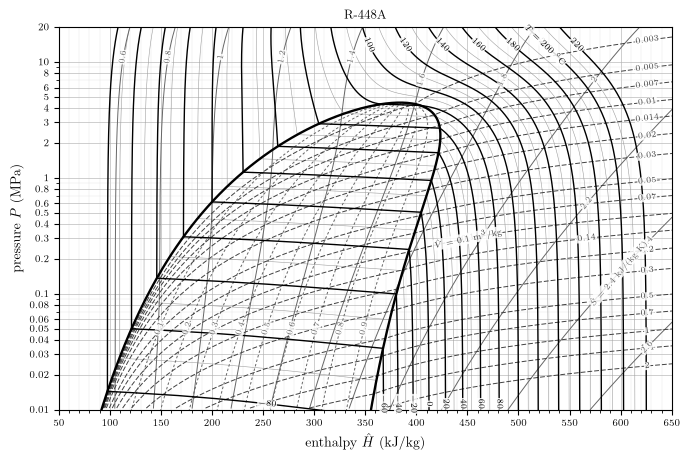

In [7]:
use_book_style()

S_LINES = [s / 10 for s in range(6, 29, 2)]                       # kJ/(kg K)
V_LINES = (0.003, 0.005, 0.007, 0.01, 0.014, 0.02, 0.03, 0.05, 0.07,
           0.1, 0.14, 0.2, 0.3, 0.5, 0.7, 1.0, 1.4, 2.0)          # m^3/kg
CHART = dict(H_lim=(50, 650), P_lim=(0.01, 20), H_grid=50, T_celsius=True,
             isotherms=range(-80, 221, 20), isotherms_minor=range(-70, 211, 20),
             isentropes=S_LINES, volumes=V_LINES,
             qualities=[i / 10 for i in range(1, 10)],
             T_label_P=14, x_label_P=0.05,
             label_fmt={"T": "${:g}$"},                          # a true minus sign
             family_labels=[("T", 200, 14, r"$T$ = 200 $^\circ$C"),
                            ("S", 2.4, 0.15, r"$\hat S$ = 2.4 kJ/(kg K)"),
                            ("V", 0.1, 0.3, r"$\hat V$ = 0.1 m$^3$/kg")])
CHART["S_label_P"] = {s: (11 if s <= 1.4 else 7 if s <= 2.0 else 0.6) for s in S_LINES}
# None sends a label to the right-hand edge: the smaller volumes reach the vapor
# region only at high pressure, and a label at 0.3 MPa would sit inside the dome.
CHART["V_label_P"] = {v: (None if v <= 0.07 else 0.3) for v in V_LINES}

fig, ax = plt.subplots(figsize=(7.0, 4.7))
ph_chart(ax, r448a, **CHART)
ax.set_title("R-448A", fontsize=9)
fig.tight_layout()
os.makedirs("pdf", exist_ok=True)
fig.savefig("pdf/PH_chart_R448A.pdf")
plt.show()

**Reading it.** Follow the $0\ ^\circ$C isotherm in from the right. It meets the dew curve
near 0.50 MPa and descends across the dome, because at constant temperature the blend
condenses as the pressure *rises*, and it reaches the bubble curve near 0.62 MPa. On a pure
fluid's chart those two pressures would be one.

**Where not to read it.** Peng&ndash;Robinson puts the saturated-liquid density of this
blend 4 % low at $0\ ^\circ$C and 8 % low at $40\ ^\circ$C, against the reference model, so
the constant-volume lines in the compressed-liquid region to the left of the dome are
qualitative. The isotherms, isentropes and the dome itself
are unaffected; the next section measures how close they are.

The chart is saved as `pdf/PH_chart_R448A.pdf`, sized to print on letter paper.

## 5. A check: one refrigeration cycle

Section 5.2 analyzes the vapor-compression refrigeration cycle on a pressure&ndash;enthalpy
chart: saturated vapor leaves the evaporator (state 1), is compressed isentropically to the
condenser pressure (2), leaves the condenser as saturated liquid (3), and is throttled at
constant enthalpy back to the evaporator pressure (4).

For a blend, "the evaporator temperature" needs a definition, because the temperature is not
constant inside the evaporator. Here state 1 is the **dew point at $-10\ ^\circ$C** and state
3 is the **bubble point at $40\ ^\circ$C**, the convention under which both states are
saturated. The same cycle computed with CoolProp's reference model is printed beside it.

In [8]:
# The same cycle from CoolProp 8.1.0's R-448A model, shifted to the IIR datum.
REF_CYCLE = dict(P_evap=0.3580, P_cond=1.8831, H1=396.43, S1=1.7588, V1=0.064155,
                 H2=436.56, T2=59.73, H3=260.92, T4=-14.28)

T_evap, T_cond = -10.0 + 273.15, 40.0 + 273.15
P_e = r448a.P_dew(T_evap)                         # evaporator: dew point at -10 C
P_c = r448a.P_bubble(T_cond)                      # condenser:  bubble point at 40 C

H1, S1, V1 = r448a.feed(T_evap, P_e, "vapor")     # 1: saturated vapor
T2 = brentq(lambda t: r448a.feed(t, P_c, "vapor")[1] - S1, T_cond, 600.0)
H2 = r448a.feed(T2, P_c, "vapor")[0]              # 2: isentropic compression
H3 = r448a.feed(T_cond, P_c, "liquid")[0]         # 3: saturated liquid
# 4: throttled at constant H into the dome; its temperature is read off the grid
Tgrid, Pgrid = r448a._row_interp("H", H3, out="T")
T4 = np.interp(np.log(P_e), np.log(Pgrid), Tgrid)

ours = dict(P_evap=P_e / 1e6, P_cond=P_c / 1e6, H1=H1, S1=S1, V1=V1,
            H2=H2, T2=T2 - 273.15, H3=H3, T4=T4 - 273.15)
labels = dict(P_evap="evaporator pressure (MPa)", P_cond="condenser pressure (MPa)",
              H1="H1, saturated vapor (kJ/kg)", S1="S1 (kJ/(kg K))",
              V1="V1 (m^3/kg)", H2="H2, after compression (kJ/kg)",
              T2="T2, discharge temperature (C)", H3="H3 = H4, saturated liquid (kJ/kg)",
              T4="T4, after the throttle (C)")
print(f"{'':<36}{'this chart':>11}{'reference':>11}")
for k, lab in labels.items():
    print(f"{lab:<36}{ours[k]:11.4g}{REF_CYCLE[k]:11.4g}")


def performance(d):
    q, w = d["H1"] - d["H3"], d["H2"] - d["H1"]
    return q, w, q / w, q / d["V1"]


print(f"\n{'':<36}{'this chart':>11}{'reference':>11}")
for lab, a, b in zip(("refrigeration effect (kJ/kg)", "compressor work (kJ/kg)",
                      "C.O.P.", "volumetric capacity (kJ/m^3)"),
                     performance(ours), performance(REF_CYCLE)):
    print(f"{lab:<36}{a:11.4g}{b:11.4g}   ({100*(a/b - 1):+.1f} %)")

                                     this chart  reference
evaporator pressure (MPa)                0.3537      0.358
condenser pressure (MPa)                  1.866      1.883
H1, saturated vapor (kJ/kg)                 399      396.4
S1 (kJ/(kg K))                            1.769      1.759
V1 (m^3/kg)                             0.06598    0.06416
H2, after compression (kJ/kg)             439.6      436.6
T2, discharge temperature (C)             60.25      59.73
H3 = H4, saturated liquid (kJ/kg)         264.4      260.9
T4, after the throttle (C)               -14.27     -14.28

                                     this chart  reference
refrigeration effect (kJ/kg)              134.6      135.5   (-0.6 %)
compressor work (kJ/kg)                   40.59      40.13   (+1.1 %)
C.O.P.                                    3.317      3.377   (-1.8 %)
volumetric capacity (kJ/m^3)               2041       2112   (-3.4 %)


The coefficient of performance agrees with the reference to 2 %, the discharge temperature
to half a kelvin, and the temperature after the throttle to 0.01 K. The largest difference is
the volumetric capacity, 3.4 % low. It traces to $\hat V_1$: Peng&ndash;Robinson gives the
saturated vapor a specific volume 3 % too large. Each of these is smaller than the
uncertainty of reading a value off a printed chart.

State 4 makes the glide visible. The refrigerant enters the evaporator at
$-14.3\ ^\circ$C and leaves it at $-10\ ^\circ$C, warming by more than 4 K while it boils at
constant pressure. Equipment ratings for zeotropic blends therefore state which temperature
they mean: the dew point, as here, or a mean of the inlet and outlet temperatures.

## What this notebook shows

- **A zeotropic blend's isotherms slope across the two-phase region.** For R-448A the bubble
  and dew temperatures at one pressure differ by 6 to 7 K at evaporator pressures, and the
  difference shrinks to zero at the mixture critical point, $82\ ^\circ$C and 4.45 MPa.
- **Peng&ndash;Robinson with four binary parameters reproduces the blend's saturation
  pressures to about 1 %.** With none it is 3.4 to 5.6 % low. The four were set from binary
  pairs, not from the blend.
- **The chart reproduces a reference refrigeration cycle** to 2 % in C.O.P. and 3.4 % in
  volumetric capacity.
- **A blend has no single evaporating temperature.** In the cycle above it boils from
  $-14.3$ to $-10\ ^\circ$C at one pressure.

## Your turn

1. **Draw the cycle.** Plot states 1&ndash;4 of §5 on the chart, joined in order. Which legs
   are vertical, which are horizontal, and which one is neither?
2. **Mean evaporating temperature.** Repeat §5 with the evaporator specified by its *mean*
   temperature, $(T_4 + T_1)/2 = -10\ ^\circ$C, instead of its dew point. By how much do the
   evaporator pressure and the C.O.P. change? (You will need to iterate, because $T_4$
   depends on the pressure.)
3. **A leak.** A slow leak from the vapor space of a receiver removes the more volatile
   components faster than the others. Remove one-tenth of the R-32 from `z`, renormalize,
   and rebuild `r448a`. How much do the evaporator pressure at a $-10\ ^\circ$C dew point and
   the glide change? Would a technician who tops up the charge with fresh R-448A restore the
   original composition?
4. **How much the $k_{ij}$ matter.** Build the chart with `PRMixture(pure)`, every
   $k_{ij} = 0$, and overlay its dome on the one above. At what pressure is the difference
   largest, and is it visible at the scale of the printed chart?
5. **Discharge temperature.** Compressor manufacturers limit discharge temperature, often to
   about $130\ ^\circ$C. Lower the evaporator dew point in §5 until $T_2$ reaches that limit,
   keeping the condenser at $40\ ^\circ$C. What is the pressure ratio there?